# Fifty Shades of Coffee: допзадание к спринту 2

Петров Мирон и Каплунова Анна

В [основном S2](stat-lab1-s2.ipynb) генерируем влажность обратным преобразованием. Здесь получаем те же распределения методом псевдонимов и отбором с отклонением. Затем применяем метод суперпозиции, чтобы посмотреть, как меняется распределение влажности при разном соотношении записей из Мексики и Гватемалы. В конце пробуем бета-распределение как отдельную теоретическую модель влажности.

1. [Данные](#данные)
2. [Метод псевдонимов](#метод-псевдонимов)
3. [Отбор с отклонением](#отбор-с-отклонением)
4. [Сравнение результатов](#сравнение-результатов)
5. [Метод суперпозиции](#метод-суперпозиции)
6. [Бета-распределение](#бета-распределение) · [Источники](#источники)

Запускаем ячейки сверху вниз. Если локального `coffee_ratings.csv` нет, ноутбук загрузит закреплённую версию из репозитория. 

## Данные

Используем тот же CSV и тот же отбор, что в [S1](stat-lab1-s1.ipynb): берём записи арабики, в которых влажность, кислотность и полнота положительны. Для самих генераторов используем только влажность. Записи с нулевой влажностью исключаем по правилу S1: неизвестно, что означает ноль в исходной базе. Положительные крайние значения оставляем.

Как и в S2, доступны три профиля: **вся арабика S1** (если страна не указана), **Мексика** и **Гватемала**. В S1 заметили различие между этими странами, а в S2 проверили, что учёт страны помогает на отложенных записях. Здесь проверяем работу алгоритмов на уже заданных частотах. Значения выдаём в долях: 0,11 соответствует 11% влажности. Диапазон 10–12% используем в сравнении, но при генерации сохраняем все отдельные значения.

In [ ]:
# Данные S1 и три профиля S2 
import hashlib
from io import BytesIO
from operator import index
from pathlib import Path
from typing import NamedTuple
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

candidates = [
    Path("coffee_ratings.csv"), Path("data/coffee_ratings.csv"),
    Path("../coffee_ratings.csv"), Path("../data/coffee_ratings.csv"),
]
csv_path = next((path for path in candidates if path.is_file()), None)
csv_url = (
    "https://raw.githubusercontent.com/Mironiks007/fifty-shades-of-coffee-stat/"
    "98b9b5e93e7626f2f703dd5c34780db5359bf8a9/coffee_ratings.csv"
)

if csv_path is not None:
    csv_bytes = csv_path.read_bytes()
else:
    with urlopen(csv_url, timeout=30) as response:
        csv_bytes = response.read()

expected_sha256 = "ae6fdd58f4a7f77397c11c2657e22be8aa8f746bdc5a74cf479e981bd3c25d5e"
if hashlib.sha256(csv_bytes).hexdigest() != expected_sha256:
    raise ValueError("Нужен тот же coffee_ratings.csv, что и в первом спринте")

coffee = pd.read_csv(BytesIO(csv_bytes))
columns = ["moisture", "acidity", "body"]
valid = coffee["species"].eq("Arabica") & coffee[columns].gt(0).all(axis=1)
prepared = coffee.loc[valid].copy()
moisture = prepared["moisture"].to_numpy()

print(f"В исходном файле: {len(coffee)} строк")
print(f"После отбора: {moisture.size} строк")
assert coffee.shape == (1339, 43) and moisture.size == 1058

class MoistureProfile(NamedTuple):
    values: np.ndarray
    counts: np.ndarray
    cumulative: np.ndarray

    @property
    def probabilities(self):
        return self.counts / self.counts.sum()


def fit_profile(sample):
    values, counts = np.unique(np.asarray(sample, dtype=float), return_counts=True)
    if not values.size or not np.isfinite(values).all():
        raise ValueError("Профилю нужна непустая выборка с конечными значениями")
    return MoistureProfile(values, counts, counts.cumsum() / counts.sum())


country_names = {"Mexico": "Мексика", "Guatemala": "Гватемала"}
profile_names = {None: "Вся арабика S1", **country_names}
profiles = {None: fit_profile(moisture)}
for country in country_names:
    sample = prepared.loc[prepared.country_of_origin.eq(country), "moisture"]
    profiles[country] = fit_profile(sample)


def range_mask(values):
    return (0.10 <= values) & (values <= 0.12)


def profile_for(country):
    if country not in profiles:
        raise ValueError("country: None, 'Mexico' или 'Guatemala'")
    return profiles[country]


def check_size(size):
    size = index(size)
    if size < 0:
        raise ValueError("Количество значений должно быть неотрицательным")
    return size


display(pd.DataFrame([
    {"Профиль": profile_names[country], "Записей": profile.counts.sum(),
     "Уровней влажности": len(profile.values),
     "Доля 10–12%, %": 100*profile.probabilities[range_mask(profile.values)].sum()}
    for country, profile in profiles.items()
]).set_index("Профиль").round(2))

В исходном файле: 1339 строк
После отбора: 1058 строк


,Записей,Уровней влажности,"Доля 10–12%, %"
Профиль,,,
Вся арабика S1,1058,22,79.77
Мексика,222,10,66.67
Гватемала,174,9,93.10


## Метод псевдонимов

Случайно выбираем ячейку таблицы и решаем, взять её значение или запасное: псевдоним

Для выбранного профиля представим $K$ одинаковых ячеек по $N$ мест: $K$ - число разных влажностей, $N$ - число записей. Если влажность $x_i$ встретилась $c_i$ раз, выделяем ей $Kc_i$ мест. Тогда всего есть $KN$ мест, а доля этой влажности равна $Kc_i/(KN)=c_i/N$

Сначала выделяем каждому значению свою ячейку. Редкие значения не заполняют её целиком, а частые занимают больше одной ячейки. Берём одну неполную ячейку и заполняем остаток мест за счёт частого значения. Оно и становится её **псевдонимом**. Повторяем, пока все ячейки не будут заполнены. Сами места в памяти не храним: на ячейку нужны только граница и номер псевдонима

Простой пример: пусть значения $A$ и $B$ встретились один и три раза. Тогда есть две ячейки по четыре места, из которых $A$ получает два, а $B$ - шесть. В первой ячейке два места отдаём $A$, ещё два - $B$. Во второй все четыре места достаются $B$. Получаем нужные вероятности: $2/8$ для $A$ и $6/8$ для $B$

При генерации равновероятно выбираем ячейку и место внутри неё. Все пары «ячейка, место» имеют вероятность $1/(KN)$. Перекладывание мест при подготовке таблицы не меняет их общего числа для каждого значения, поэтому генератор даёт ровно заданные вероятности. Поскольку у нас есть целочисленные частоты, границы ячеек тоже считаем в целых числах

In [ ]:
# Таблицы псевдонимов и пример генерации
def build_alias(counts):
    """Строим таблицу из целочисленных частот."""
    counts = [index(c) for c in counts]
    n, k = sum(counts), len(counts)
    if n <= 0 or any(c < 0 for c in counts):
        raise ValueError("Нужны неотрицательные частоты с положительной суммой")

    # Остаток мест для каждого значения и вместимость одной ячейки n
    remaining = [k * c for c in counts]
    small = [i for i, m in enumerate(remaining) if m < n]
    large = [i for i, m in enumerate(remaining) if m >= n]
    cutoff = np.full(k, n, dtype=int)
    alias = np.arange(k)

    while small and large:
        i = small.pop()
        j = large.pop()
        cutoff[i] = remaining[i]
        alias[i] = j
        remaining[j] -= n - remaining[i]
        (small if remaining[j] < n else large).append(j)

    # Необработанные ячейки уже заполнены своим значением
    assert all(remaining[i] == n for i in small + large)
    return cutoff, alias, n


def alias_indices(bucket, slot, cutoff, alias):
    return np.where(slot < cutoff[bucket], bucket, alias[bucket])


alias_tables = {country: build_alias(profile.counts) for country, profile in profiles.items()}


def sample_alias(size, rng, country):
    profile = profile_for(country)
    cutoff, alias, capacity = alias_tables[country]
    bucket = rng.integers(0, len(profile.values), size=size)
    slot = rng.integers(0, capacity, size=size)
    return profile.values[alias_indices(bucket, slot, cutoff, alias)]


def generate_moisture_alias(size, seed=None, *, country=None):
    """Генерируем влажность в долях методом псевдонимов."""
    return sample_alias(check_size(size), np.random.default_rng(seed), country)


cutoff, alias, capacity = alias_tables[None]
values = profiles[None].values
i = int(np.flatnonzero(cutoff < capacity)[0])
print(f"Общий профиль: у ячейки {100*values[i]:g}% первые {cutoff[i]} из {capacity} мест свои, "
      f"остальные {capacity-cutoff[i]} отданы псевдониму {100*values[alias[i]]:g}%.")
print("Мексика, пример в процентах:", 100*generate_moisture_alias(10, seed=42, country="Mexico"))

Общий профиль: у ячейки 1% первые 330 из 1058 мест свои, остальные 728 отданы псевдониму 10%.
Мексика, пример в процентах: [11. 12. 14. 11. 11. 12. 11. 14. 12. 11.]


### Точная проверка псевдонимов

Для каждого профиля перебираем все $KN$ пар «ячейка, место». Например, в общем профиле их $22\cdot1058=23\,276$. Проверяем, что ровно $Kc_i$ пар возвращают значение $x_i$. Эта проверка охватывает и редкие значения. Случайные серии сравним отдельно ниже.

In [ ]:
# Перебор всех входов для псевдонимов
alias_exact = {}
for country, profile in profiles.items():
    k = len(profile.values)
    cutoff, alias, capacity = alias_tables[country]
    buckets = np.repeat(np.arange(k), capacity)
    slots = np.tile(np.arange(capacity), k)
    exact = np.bincount(alias_indices(buckets, slots, cutoff, alias), minlength=k)
    np.testing.assert_array_equal(exact, k * profile.counts)
    alias_exact[country] = len(buckets)
    print(f"{profile_names[country]}: перебрали {len(buckets)} пар; совпали частоты всех уровней ({k}).")

Вся арабика S1: перебрали 23276 пар; совпали частоты всех уровней (22).
Мексика: перебрали 2220 пар; совпали частоты всех уровней (10).
Гватемала: перебрали 1566 пар; совпали частоты всех уровней (9).


## Отбор с отклонением

Сначала предлагаем одну из $K$ влажностей выбранного профиля с одинаковой вероятностью. В этом профиле значение $x_i$ встретилось $c_i$ раз, а наибольшую частоту обозначаем $c_{\max}$. Берём целое $u$ от 0 до $c_{\max}-1$ и принимаем значение, если $u<c_i$. Если не приняли, предлагаем следующее

В общем профиле $K=22$, а $c_{\max}=381$. В нём влажность 11% принимаем каждый раз, когда она выпадает кандидатом: у неё максимальная частота. Влажность 1% встретилась 15 раз, поэтому при предложении 1% принимаем примерно 4 попытки из 100. Так равновероятные предложения превращаются в результаты с разными вероятностями

Вероятность предложить и принять значение $x_i$ равна $c_i/(Kc_{\max})$. Сумма этих вероятностей по всем значениям даёт шанс принять любую попытку:

$$
P(\text{принятие})=\sum_i \frac{c_i}{Kc_{\max}}=\frac{N}{Kc_{\max}}
$$

Среди принятых результатов доля $x_i$ в модели равна

$$
P(\text{кандидат}=x_i\mid\text{принятие})=\frac{c_i/(Kc_{\max})}{N/(Kc_{\max})}=\frac{c_i}{N}
$$

Это те же вероятности, что у выбранного профиля S1. Попытки повторяем независимо, поэтому среднее число предложений на одно принятие равно $1/P(\text{принятие})=Kc_{\max}/N$

In [ ]:
# Генератор с отбором и число попыток
def accept_candidate(candidate, ticket, counts):
    return ticket < counts[candidate]


def generate_moisture_rejection(size, seed=None, *, country=None):
    """Возвращаем влажности в долях и число попыток до последнего принятия."""
    profile = profile_for(country)
    values, counts = profile.values, profile.counts
    n, k, max_count = int(counts.sum()), len(values), int(counts.max())
    size = check_size(size)
    rng = np.random.default_rng(seed)
    result = np.empty(size, dtype=values.dtype)
    written = attempts = 0
    while written < size:
        remaining = size - written
        batch = min(32_768, (remaining * k * max_count + n - 1) // n)
        candidates = rng.integers(0, k, size=batch)
        tickets = rng.integers(0, max_count, size=batch)
        accepted = np.flatnonzero(accept_candidate(candidates, tickets, counts))[:remaining]
        result[written:written + accepted.size] = values[candidates[accepted]]
        written += accepted.size
        # Число предложений до последнего нужного результата, без остатка пакета.
        attempts += int(accepted[-1]) + 1 if written == size else batch
    return result, attempts

### Точная проверка отбора с отклонением

Для каждого профиля перебираем $Kc_{\max}$ пар «кандидат, целое число». Для значения $x_i$ должно приниматься ровно $c_i$ пар. В общем профиле всего $22\cdot381=8382$ пары, из них принимаются 1058. Доля принятых пар определяет среднее число предложений на одно сгенерированное значение.

In [ ]:
# Перебор всех входов для отбора с отклонением
rejection_exact = {}
for country, profile in profiles.items():
    k, max_count = len(profile.values), int(profile.counts.max())
    candidates = np.repeat(np.arange(k), max_count)
    tickets = np.tile(np.arange(max_count), k)
    accepted = accept_candidate(candidates, tickets, profile.counts)
    exact = np.bincount(candidates[accepted], minlength=k)
    np.testing.assert_array_equal(exact, profile.counts)
    rejection_exact[country] = len(candidates)
    print(f"{profile_names[country]}: принято {accepted.sum()} из {len(candidates)} пар; "
          f"совпали частоты всех уровней ({k}).")

Вся арабика S1: принято 1058 из 8382 пар; совпали частоты всех уровней (22).
Мексика: принято 222 из 800 пар; совпали частоты всех уровней (10).
Гватемала: принято 174 из 684 пар; совпали частоты всех уровней (9).


## Сравнение результатов

Для каждого метода и каждого профиля генерируем по 100 000 значений. В таблице сравниваем среднее, долю влажности 11% и долю в диапазоне 10–12%. Также показываем наибольшую разницу частот по отдельным уровням. Даже при точных вероятностях частоты в конечной серии меняются от запуска к запуску.

Пример запуска: `generate_moisture_alias(10, seed=42, country="Mexico")` вернёт десять влажностей в долях. `generate_moisture_rejection(10, seed=42, country="Mexico")` дополнительно вернёт число предложений до десятого принятия. Для Гватемалы указываем `country="Guatemala"`, для общего профиля опускаем параметр.

In [ ]:
# Сравнение частот и числа попыток на трёх профилях
size = 100_000
result_rows, attempt_rows, sample_p = [], [], {}
for i, (country, profile) in enumerate(profiles.items()):
    k = len(profile.values)
    p = profile.probabilities
    alias_sample = generate_moisture_alias(size, seed=2026 + 100*i, country=country)
    rejection_sample, attempts = generate_moisture_rejection(size, seed=2027 + 100*i, country=country)
    sample_p[country] = {}
    for name, sample in [("Данные S1", None), ("Псевдонимы", alias_sample),
                         ("Отбор с отклонением", rejection_sample)]:
        if sample is None:
            freq = p
        else:
            assert len(sample) == size and np.isin(sample, profile.values).all()
            positions = np.searchsorted(profile.values, sample)
            freq = np.bincount(positions, minlength=k) / size
            sample_p[country][name] = freq
        result_rows.append({
            "Профиль": profile_names[country], "Способ": name,
            "Среднее, %": 100*(freq @ profile.values),
            "Доля 11%, %": 100*freq[profile.values == .11].sum(),
            "Доля 10–12%, %": 100*freq[range_mask(profile.values)].sum(),
            "Макс. разница частот, п. п.": 100*np.max(np.abs(freq - p)),
        })
    p_accept = profile.counts.sum() / rejection_exact[country]
    attempt_rows.append({
        "Профиль": profile_names[country], "Принятие: расчёт, %": 100*p_accept,
        "Принятие: прогон, %": 100*size/attempts,
        "Попыток на значение: расчёт": 1/p_accept,
        "Попыток на значение: прогон": attempts/size,
    })

comparison = pd.DataFrame(result_rows).set_index(["Профиль", "Способ"])
attempt_summary = pd.DataFrame(attempt_rows).set_index("Профиль")
display(comparison.round(3))
display(attempt_summary.round(2))

Среднее, %  Доля 11%, %  Доля 10–12%, %  Макс. разница частот, п. п.
Профиль        Способ                                                                                   
Вся арабика S1 Данные S1                11.000       36.011          79.773                        0.000
               Псевдонимы               11.000       35.984          79.893                        0.218
               Отбор с отклонением      11.010       36.044          79.843                        0.098
Мексика        Данные S1                12.077       24.324          66.667                        0.000
               Псевдонимы               12.080       24.121          66.658                        0.223
               Отбор с отклонением      12.071       24.254          66.733                        0.150
Гватемала      Данные S1                10.638       43.678          93.103                        0.000
               Псевдонимы               10.638       43.519          93.089                        0.159
               Отбор с отклонением      10.636       43.622          93.073                        0.056

,"Принятие: расчёт, %","Принятие: прогон, %",Попыток на значение: расчёт,Попыток на значение: прогон
Профиль,,,,
Вся арабика S1,12.62,12.59,7.92,7.94
Мексика,27.75,27.69,3.60,3.61
Гватемала,25.44,25.39,3.93,3.94


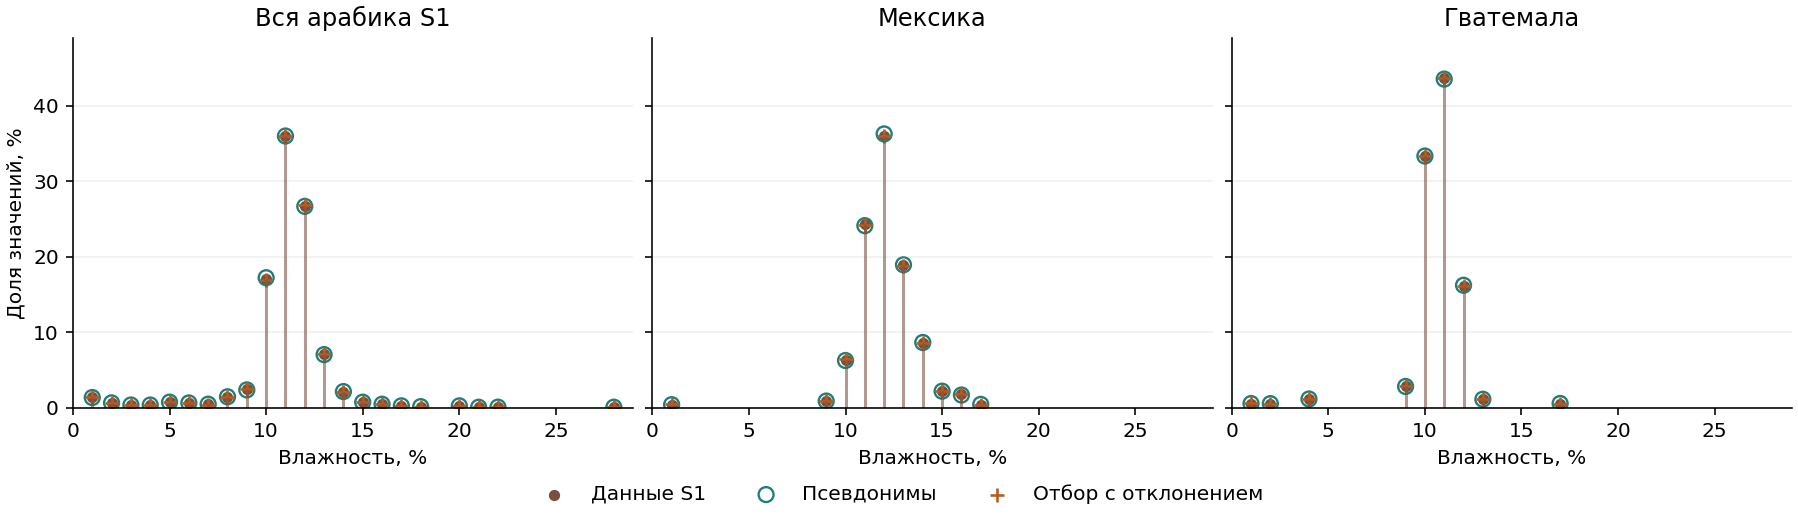

In [ ]:
# График частот для трёх профилей
fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.6), sharex=True, sharey=True, layout="constrained")
top = max(100*max(p.probabilities.max(), *(v.max() for v in sample_p[country].values()))
          for country, p in profiles.items())
for ax, (country, profile) in zip(axes, profiles.items()):
    x = 100*profile.values
    ax.vlines(x, 0, 100*profile.probabilities, color="#79503e", alpha=.58)
    ax.scatter(x, 100*profile.probabilities, s=21, color="#79503e", label="Данные S1")
    ax.scatter(x, 100*sample_p[country]["Псевдонимы"], s=55, facecolors="none",
               edgecolors="#1f7e78", linewidths=1.15, label="Псевдонимы")
    ax.scatter(x, 100*sample_p[country]["Отбор с отклонением"], s=55, marker="+",
               color="#b35d22", linewidths=1.3, label="Отбор с отклонением")
    ax.set(title=profile_names[country], xlabel="Влажность, %")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=.2)
axes[0].set(ylabel="Доля значений, %", ylim=(0, top*1.12), xlim=(0, 29))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
plt.show()

| Способ | Что делаем для одного значения |
|---|---|
| Обратная функция из S2 | Ищем нужный интервал двоичным поиском по накопленным частотам |
| Псевдонимы | Заранее строим таблицу. На каждый результат выбираем одну пару «ячейка, место» и проверяем границу |
| Отбор с отклонением | Предлагаем пары до первого принятия. Среднее число предложений зависит от $K$, $N$ и наибольшей частоты $c_{\max}$ |

Перебор подтверждает, что оба дополнительных алгоритма дают точные вероятности каждого из трёх профилей. По случайным сериям видно то же различие, что в S1 и S2: в диапазон 10–12% попадает около двух третей значений Мексики и больше 90% значений Гватемалы.

Отбор с отклонением в общем профиле требует около восьми предложений на результат, а в профилях стран - около четырёх. Состав профиля меняет число предложений; по одному прогону нельзя объявить один метод точнее другого. Время работы не замеряли. Эти результаты показывают, как генераторы воспроизводят частоты таблицы. Проверку на отложенных записях оставляем в основном S2.

## Метод суперпозиции

В S1 и S2 у нас уже есть два профиля влажности: для Мексики и для Гватемалы. Теперь представим, что формируем поток записей из этих стран и можем задать их соотношение. Например, хотим понять, как изменится доля влажности 10–12%, если вместо половины записей из Мексики брать 80%.

**Как генерируем одну запись.** Задаём $w$ - вероятность выбрать Мексику. Берём равномерное число $U$. При $U<w$ выбираем Мексику, иначе Гватемалу. Затем получаем влажность из профиля выбранной страны методом псевдонимов. Для следующей записи снова выбираем страну. Поэтому при $w=0{,}8$ доля мексиканских записей в конечной серии может немного отличаться от 80%. Мы моделируем происхождение отдельных записей, а не влажность физической смеси зёрен.

**Почему это работает.** Влажность $x$ может выпасть двумя способами: выбираем Мексику и получаем $x$ в её профиле, либо выбираем Гватемалу и получаем $x$ в её профиле. По формуле полной вероятности складываем вероятности этих двух случаев:

$$
P(X=x)=w\,P(X=x\mid C=\text{Мексика})+(1-w)\,P(X=x\mid C=\text{Гватемала})
$$

Если уровень влажности в одной стране не встретился, её вклад для этого уровня равен нулю. Так же считаем вероятность для целого диапазона. Например, в 10–12% попадают 148 из 222 записей Мексики и 162 из 174 записей Гватемалы. При равных весах получаем

$$
P(10\%\le X\le12\%)=0{,}5\cdot\frac{148}{222}+0{,}5\cdot\frac{162}{174}\approx0{,}799
$$

При $w=0{,}8$ та же формула даёт около 72,0%. Это проверяем ниже. Вес выбираем для сценария: ни 50/50, ни 80/20 не претендуют на описание реальных поставок. Сам принцип «сначала выбираем компонент, потом генерируем из него» описан у [Люка Девруа, §1.6 *Mixture methods*](https://luc.devroye.org/handbooksimulation1.pdf#page=7).

In [ ]:
# Суперпозиция: выбор страны и генерация влажности
mixture_support = np.union1d(profiles["Mexico"].values, profiles["Guatemala"].values)


def check_weight(mexico_weight):
    w = float(mexico_weight)
    if not 0 <= w <= 1:
        raise ValueError("Вес Мексики должен быть от 0 до 1")
    return w


def mixture_probabilities(mexico_weight):
    """Считаем теоретические вероятности смеси на общей сетке значений."""
    w = check_weight(mexico_weight)
    probabilities = np.zeros(len(mixture_support))
    for country, weight in [("Mexico", w), ("Guatemala", 1-w)]:
        profile = profiles[country]
        positions = np.searchsorted(mixture_support, profile.values)
        probabilities[positions] += weight * profile.probabilities
    return probabilities


def generate_moisture_mixture(size, mexico_weight=0.5, seed=None):
    """Возвращаем влажность в долях и метку страны для каждой записи."""
    size = check_size(size)
    w = check_weight(mexico_weight)
    rng = np.random.default_rng(seed)
    is_mexico = rng.random(size) < w
    values = np.empty(size, dtype=float)
    n_mexico = int(is_mexico.sum())
    values[is_mexico] = sample_alias(n_mexico, rng, "Mexico")
    values[~is_mexico] = sample_alias(size-n_mexico, rng, "Guatemala")
    return values, np.where(is_mexico, "Mexico", "Guatemala")


values_demo, countries_demo = generate_moisture_mixture(8, mexico_weight=0.8, seed=42)
display(pd.DataFrame({"Страна": pd.Series(countries_demo).map(profile_names),
                      "Влажность, %": 100*values_demo}))

,Страна,"Влажность, %"
0,Мексика,13.0
1,Мексика,12.0
2,Гватемала,10.0
3,Мексика,12.0
4,Мексика,11.0
5,Гватемала,9.0
6,Мексика,13.0
7,Мексика,11.0


### Проверяем смесь

Есть простой способ проверить расчёт вероятностей без случайных чисел. Если взять веса пропорционально числу записей, то есть 222/396 для Мексики и 174/396 для Гватемалы, смесь должна дать те же частоты, что объединённая таблица этих двух стран. Сначала проверяем это равенство для каждого уровня влажности.

Потом генерируем по 100 000 значений для 50/50 и 80/20. Сравниваем с расчётом долю выбранных стран, среднюю влажность и долю в диапазоне 10–12%. Чтобы проверить не только этот диапазон, считаем максимальную разницу между расчётной и наблюдаемой частотой по всем уровням. Небольшие отличия в конечной серии ожидаемы.

In [ ]:
# Сравнение расчётных и наблюдаемых частот смеси
both = prepared.loc[prepared.country_of_origin.isin(["Mexico", "Guatemala"]), "moisture"]
combined = fit_profile(both)
w_empirical = profiles["Mexico"].counts.sum() / combined.counts.sum()
np.testing.assert_array_equal(mixture_support, combined.values)
np.testing.assert_allclose(mixture_probabilities(w_empirical), combined.probabilities, atol=1e-15, rtol=0)
print("При весах 222/396 и 174/396 совпали частоты всех уровней объединённой таблицы двух стран.")

mix_size = 100_000
inside_range = range_mask(mixture_support)
mix_rows, mix_plot = [], {}
for w, seed in [(0.5, 2031), (0.8, 2032)]:
    expected = mixture_probabilities(w)
    generated, country_labels = generate_moisture_mixture(mix_size, mexico_weight=w, seed=seed)
    assert len(generated) == mix_size and np.isin(generated, mixture_support).all()
    for country in ("Mexico", "Guatemala"):
        assert np.isin(generated[country_labels == country], profiles[country].values).all()
    freq = np.bincount(np.searchsorted(mixture_support, generated), minlength=len(mixture_support))/mix_size
    scenario = f"{100*w:.0f}/{100*(1-w):.0f}"
    mix_rows.append({"Мексика / Гватемала": scenario,
                     "Мексика в серии, %": 100*np.mean(country_labels == "Mexico"),
                     "Среднее: расчёт, %": 100*(expected @ mixture_support),
                     "Среднее: серия, %": 100*(freq @ mixture_support),
                     "Доля 10–12%: расчёт, %": 100*expected[inside_range].sum(),
                     "Доля 10–12%: серия, %": 100*freq[inside_range].sum(),
                     "Макс. разница частот, п. п.": 100*np.max(np.abs(freq-expected))})
    mix_plot[scenario] = (expected, freq)

display(pd.DataFrame(mix_rows).set_index("Мексика / Гватемала").round(3))

При весах 222/396 и 174/396 совпали частоты всех уровней объединённой таблицы двух стран.


,"Мексика в серии, %","Среднее: расчёт, %","Среднее: серия, %","Доля 10–12%: расчёт, %","Доля 10–12%: серия, %","Макс. разница частот, п. п."
Мексика / Гватемала,,,,,,
50/50,49.89,11.357,11.351,79.885,79.965,0.316
80/20,80.17,11.789,11.788,71.954,71.780,0.204


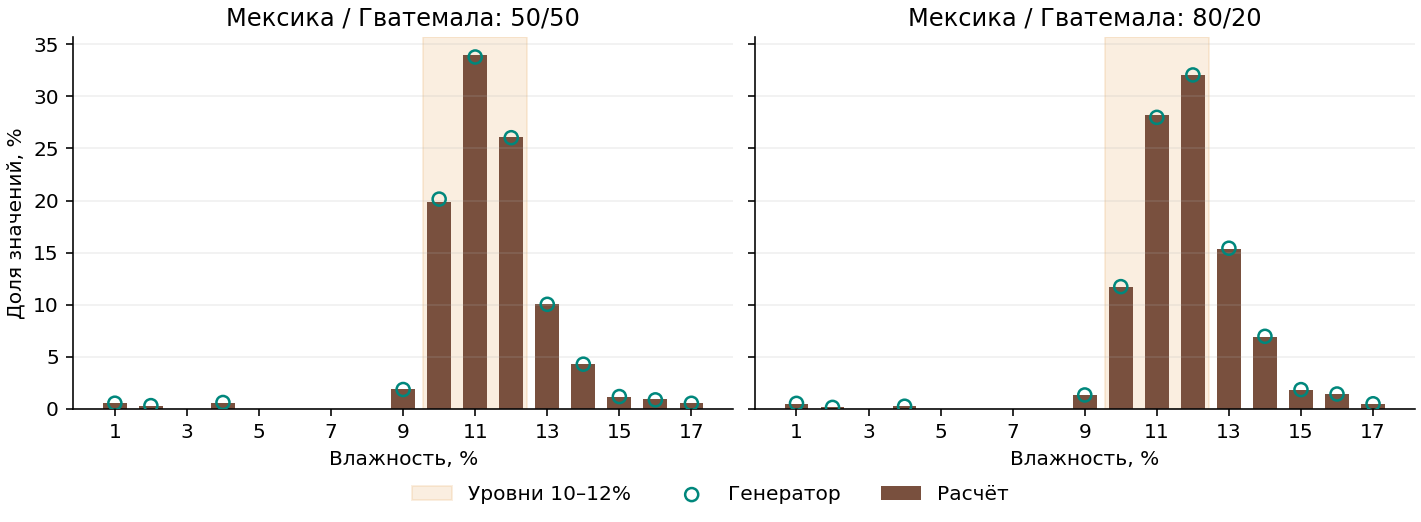

In [ ]:
# График распределений для двух смесей
fig, axes = plt.subplots(1, 2, figsize=(9.8, 3.6), sharex=True, sharey=True, layout="constrained")
x = 100*mixture_support
for ax, (scenario, (expected, freq)) in zip(axes, mix_plot.items()):
    ax.axvspan(9.55, 12.45, color="#e9b475", alpha=.22, label="Уровни 10–12%")
    ax.bar(x, 100*expected, width=.66, color="#79503e", label="Расчёт")
    ax.scatter(x, 100*freq, s=42, facecolors="none", edgecolors="#00877c",
               linewidths=1.25, label="Генератор", zorder=3)
    ax.set(title=f"Мексика / Гватемала: {scenario}", xlabel="Влажность, %", xticks=range(1, 18, 2))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("Доля значений, %")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
plt.show()

**Что получилось.** При увеличении веса Мексики с 50% до 80% расчётная доля влажности 10–12% падает примерно на 8 процентных пунктов, а средняя влажность растёт. Эти результаты не противоречат друг другу: в мексиканском профиле больше значений выше 12%. Прогон воспроизводит оба изменения. Так можно оценить, что случится с распределением при смене состава записей, используя уже рассчитанные профили стран.

## Бета-распределение

До этого мы брали вероятности непосредственно из частот S1. Теперь проверим, можно ли описать общий профиль арабики теоретическим законом с двумя параметрами. Влажность записана в долях, поэтому для скрытого значения $X$ возьмём бета-распределение: оно задано на интервале от 0 до 1. Его параметры $a$ и $b$ задают форму плотности:

$$
f(x)=\frac{x^{a-1}(1-x)^{b-1}}{B(a,b)}, \qquad a,b>0,\quad 0<x<1.
$$

В S1 записаны целые проценты. К примеру, запись 11% в нашей модели соответствует долям от 0,105 до 0,115. Это допущение для сравнения на одной сетке, а не утверждение о точности измерительного прибора. Если $F$ - функция распределения $X$, то вероятность записи $k$ процентов после исключения нулей равна

$$
p_k=\frac{F(u_k)-F(l_k)}{1-F(0{,}005)},\quad
l_k=\frac{k-0{,}5}{100},\quad
u_k=\min\!\left(1,\frac{k+0{,}5}{100}\right),\quad k=1,\ldots,100.
$$

В знаменателе вероятность того, что значение после округления положительно: нулевые записи уже исключены в S1. Подбираем $a$ и $b$ по всем 1058 записям. Если значение $k$ встретилось $c_k$ раз, его вклад в логарифм правдоподобия равен $c_k\ln p_k$. Ищем параметры, при которых сумма этих вкладов максимальна.

Для генерации берём равномерное число $U$, переводим его в интервал от $F(0{,}005)$ до 1 и применяем обратную функцию $F^{-1}$. Полученную долю округляем до целых процентов. Алгоритм обратной функции нам уже знаком по S2; здесь меняется сам закон, из которого генерируем.

In [ ]:
# Подгонка бета-распределения и генерация
from scipy import optimize, special

beta_levels = np.arange(1, 101)
beta_left = (beta_levels - .5) / 100
beta_right = np.minimum(1, (beta_levels + .5) / 100)
beta_observed_pct = np.rint(100*moisture).astype(int)
np.testing.assert_allclose(100*moisture, beta_observed_pct, rtol=0, atol=1e-12)
beta_observed_counts = np.bincount(beta_observed_pct, minlength=101)[1:]


def beta_record_prob(a, b, select=slice(None)):
    lo, hi = beta_left[select], beta_right[select]
    upper_cdf = special.betainc(a, b, hi)
    # В правом хвосте точнее вычитать вероятности превышения.
    mass = np.where(upper_cdf <= .5,
                    upper_cdf - special.betainc(a, b, lo),
                    special.betaincc(a, b, lo) - special.betaincc(a, b, hi))
    return mass / special.betaincc(a, b, .005)


def fit_rounded_beta(counts, start=None):
    present = counts > 0
    if start is None:
        x = beta_levels / 100
        weights = counts / counts.sum()
        mean = weights @ x
        variance = weights @ (x - mean)**2
        factor = mean*(1-mean)/variance - 1
        start = np.array([mean, 1-mean])*factor

    def neg_log_likelihood(log_shapes):
        p = beta_record_prob(*np.exp(log_shapes), select=present)
        if not np.all(np.isfinite(p) & (p > 0)):
            return np.inf
        return -counts[present] @ np.log(p)

    result = optimize.minimize(neg_log_likelihood, np.log(start), method="Nelder-Mead",
                               options={"xatol": 1e-7, "fatol": 1e-8})
    if not result.success or not np.isfinite(result.fun):
        raise RuntimeError(f"Не удалось подобрать параметры: {result.message}")
    return np.exp(result.x)


def generate_rounded_beta(size, a, b, seed=None):
    u = np.random.default_rng(seed).random(check_size(size))
    lower = special.betainc(a, b, .005)
    x = special.betaincinv(a, b, lower + (1-lower)*u)
    return np.rint(100*x).astype(int)  # результат в целых процентах


beta_a, beta_b = fit_rounded_beta(beta_observed_counts)
beta_expected = beta_record_prob(beta_a, beta_b)
np.testing.assert_allclose(beta_expected.sum(), 1, rtol=0, atol=1e-12)
beta_generated = generate_rounded_beta(100_000, beta_a, beta_b, seed=9470)
assert ((1 <= beta_generated) & (beta_generated <= 100)).all()
beta_sample_prob = np.bincount(beta_generated, minlength=101)[1:] / len(beta_generated)
beta_empirical = beta_observed_counts / beta_observed_counts.sum()
print(f"Подобранные параметры: a = {beta_a:.3f}; b = {beta_b:.3f}")

Подобранные параметры: a = 12.902; b = 104.569


### Проверка модели

Сравниваем частоты S1, вероятности по формуле и 100 000 сгенерированных значений. Для проверки всего распределения берём наибольшее расхождение $D$ между накопленными долями, как в S2. Поскольку здесь параметры подбирались по данным, в каждой из 499 контрольных выборок того же размера заново оцениваем оба параметра. Для этих выборок можно сразу генерировать количества записей на каждом уровне по рассчитанным вероятностям: это даёт те же частоты, что генерация отдельных значений с округлением. Проверку трактуем при допущении независимости записей.

Максимальный разрыв CDF: 23.68 п. п.
Контрольных выборок с D не меньше наблюдаемого: 0 из 499; p = 0.002.


,"Среднее, %","Ст. отклонение, п. п.","Доля 11%, %","Доля 10–12%, %"
S1 (эмпирический профиль),11.00,2.28,36.01,79.77
Бета: по формуле,10.98,2.89,13.66,39.58
Бета: 100 000 значений,10.97,2.89,13.44,39.33


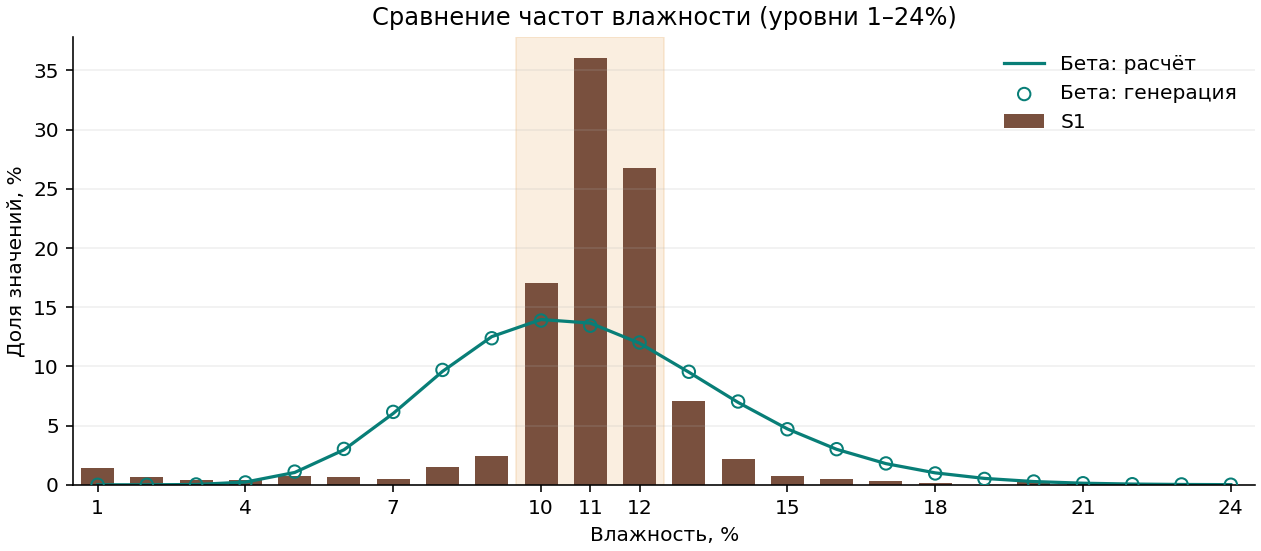

In [ ]:
# Частоты, график и проверка согласия
def beta_summary(p):
    mean = p @ beta_levels
    sd = np.sqrt(p @ (beta_levels - mean)**2)
    return [mean, sd, 100*p[beta_levels == 11].sum(),
            100*p[(beta_levels >= 10) & (beta_levels <= 12)].sum()]


beta_table = pd.DataFrame(
    [beta_summary(p) for p in [beta_empirical, beta_expected, beta_sample_prob]],
    index=["S1 (эмпирический профиль)", "Бета: по формуле", "Бета: 100 000 значений"],
    columns=["Среднее, %", "Ст. отклонение, п. п.", "Доля 11%, %", "Доля 10–12%, %"],
)
display(beta_table.round(2))


def beta_cdf_distance(counts, p):
    return np.max(np.abs(counts.cumsum()/counts.sum() - p.cumsum()))


beta_d = beta_cdf_distance(beta_observed_counts, beta_expected)
beta_rng = np.random.default_rng(9471)
beta_trials = 499
beta_exceed = 0
for trial_counts in beta_rng.multinomial(len(moisture), beta_expected/beta_expected.sum(), size=beta_trials):
    trial_shapes = fit_rounded_beta(trial_counts, start=(beta_a, beta_b))
    trial_d = beta_cdf_distance(trial_counts, beta_record_prob(*trial_shapes))
    beta_exceed += int(trial_d >= beta_d)
beta_p = (beta_exceed + 1)/(beta_trials + 1)
print(f"Максимальный разрыв CDF: {100*beta_d:.2f} п. п.")
print(f"Контрольных выборок с D не меньше наблюдаемого: {beta_exceed} из {beta_trials}; "
      f"p = {beta_p:.3f}.")

fig, ax = plt.subplots(figsize=(8.7, 3.8), layout="constrained")
zoom = beta_levels <= 24
ax.axvspan(9.5, 12.5, color="#e9b475", alpha=.22)
ax.bar(beta_levels[zoom], 100*beta_empirical[zoom], width=.67, color="#79503e", label="S1")
ax.plot(beta_levels[zoom], 100*beta_expected[zoom], color="#087e77", lw=1.6, label="Бета: расчёт")
ax.scatter(beta_levels[zoom], 100*beta_sample_prob[zoom], s=38, facecolors="none",
           edgecolors="#087e77", zorder=3, label="Бета: генерация")
ax.set(xlabel="Влажность, %", ylabel="Доля значений, %", xlim=(.5,24.5),
       title="Сравнение частот влажности (уровни 1–24%)")
ax.set_xticks(np.r_[1, 4, 7, 10, 11, 12, 15, 18, 21, 24])
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=.2)
ax.legend(frameon=False)
plt.show()

**Вывод.** По средней влажности модель близка к S1: около 10,98% против 11,00%. Но она даёт около 40% значений в диапазоне 10–12%, а в S1 их около 80%. На уровне 11% разница тоже большая: около 14% по модели против 36% в S1. Разрыв видно и по накопленным долям: ни одна из 499 контрольных выборок не дала такого же или большего $D$. Для этой проверки $p=0{,}002$ - минимальное значение при 499 повторах, поэтому отвергаем модель на уровне 0,05. Как дополнительный теоретический закон её реализовали и проверили; для воспроизведения влажности S1 оставляем эмпирический профиль.

## Источники

- L. Devroye. [*Non-Uniform Random Variate Generation*, гл. III, §4 и §5.1](https://luc.devroye.org/LucDevroye-NonUniformRandomVariateGeneration-10.1007_978-1-4613-8643-8-1986-.pdf): метод псевдонимов и отбор с отклонением для дискретных распределений.
- M. D. Vose. [*A Linear Algorithm for Generating Random Numbers with a Given Distribution*](https://doi.org/10.1109/32.92917), *IEEE Transactions on Software Engineering*, 1991: построение таблицы псевдонимов; для наших частот пороги считаем в целых числах.
- L. Devroye. [*Non-Uniform Random Variate Generation*, §1.6 *Mixture methods*](https://luc.devroye.org/handbooksimulation1.pdf#page=7), в *Handbooks in Operations Research and Management Science*, т. 13: генерация из смеси через выбор компонента.
- SciPy. [*Beta distribution*](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.beta.html) - плотность, параметры формы и обратная функция распределения. [*Goodness of fit*](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html) - повторная подгонка в контрольных выборках; здесь применяем её к округлённым записям.
- [S1](stat-lab1-s1.ipynb): происхождение данных, отбор и сравнение стран. [S2](stat-lab1-s2.ipynb): обратное преобразование, те же три профиля и проверка на отложенных записях.